# 02b Percentiles dentro de la cohorte de lanzamiento

**Documento relacionado:** [`docs/03-analisis-exploratorio.md`](../docs/03-analisis-exploratorio.md)

**Origen:** convertido del script `percentilesPorCohorte.py`, que se eliminó de `borradores/` al pasar a este notebook.

## Objetivo

Comparar cada juego solo contra los lanzados el mismo año, para neutralizar el sesgo de exposición: un juego de 2012 lleva 14 años acumulando reseñas y uno de 2024 apenas dos.

| Entradas | Salidas |
|---|---|
| `steam_games.csv.gz` (versión 2026-11-19) | `reports/figures/percentilesCohorte.png`, `reports/metrics/percentilesCohorte_resumen.csv`, `data/processed/percentilesCohorte_juegos.csv` (no se versiona) |

## Configuración

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Rutas del repositorio (el notebook vive en notebooks/)
rootDir = Path('..').resolve()
figuresDir = rootDir / 'reports' / 'figures'
metricsDir = rootDir / 'reports' / 'metrics'
processedDir = rootDir / 'data' / 'processed'
interimDir = rootDir / 'data' / 'interim'
for outPath in (figuresDir, metricsDir, processedDir, interimDir):
    outPath.mkdir(parents=True, exist_ok=True)

# Datos: versión del 2026-11-19. Se busca primero la variable de entorno STEAM_GAMES_CSV,
# luego data/raw/ y por último la carpeta Proyecto Final/Datos (fuera del repositorio).
dataCandidates = [
    Path(os.environ['STEAM_GAMES_CSV']) if 'STEAM_GAMES_CSV' in os.environ else None,
    rootDir / 'data' / 'raw' / 'steam_games.csv.gz',
    rootDir / 'data' / 'raw' / 'steam_games.csv',
    rootDir.parents[1] / 'Datos' / 'steam_games.csv.gz',
]
dataPath = next((p for p in dataCandidates if p is not None and p.exists()), None)
if dataPath is None:
    raise FileNotFoundError('No se encontró steam_games.csv(.gz); colócalo en data/raw/ o define STEAM_GAMES_CSV')
print('Datos:', dataPath.name)

snapshotDate = pd.Timestamp('2026-11-19')   # fecha de corte de la versión del dataset

# Fuente latina + respaldo CJK (macOS: Hiragino/PingFang; Linux: Noto CJK). Solo las instaladas.
installedFonts = {f.name for f in fm.fontManager.ttflist}
cjkFonts = [f for f in ('Hiragino Sans GB', 'PingFang SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'Noto Sans CJK JP')
            if f in installedFonts]
plt.rcParams['font.family'] = ['DejaVu Sans'] + cjkFonts
pd.set_option('display.width', 200)

minAgeMonths = 12      # excluir juegos con < 12 meses en tienda
minCohortSize = 200    # años más pequeños se agrupan en una cohorte inicial
minReviewsRatio = 10   # mínimo de reseñas para el percentil de % positivas

Datos: steam_games.csv.gz


## Carga

In [2]:
gamesDf = pd.read_csv(dataPath, low_memory=False, keep_default_na=False, na_values=[''])
nTotal = len(gamesDf)

releaseDate = pd.to_datetime(gamesDf['release_date'], errors='coerce', format='mixed')
positiveCount = pd.to_numeric(gamesDf['positive'], errors='coerce')
negativeCount = pd.to_numeric(gamesDf['negative'], errors='coerce')

workDf = pd.DataFrame({
    'app_id': gamesDf['app_id'],
    'name': gamesDf['name'],
    'releaseDate': releaseDate,
    'positive': positiveCount,
    'negative': negativeCount,
})
workDf['reviewCount'] = workDf['positive'] + workDf['negative']
workDf['ageDays'] = (snapshotDate - workDf['releaseDate']).dt.days

## Filtros y cohortes

Se excluyen los juegos sin fecha o sin conteo de reseñas y los que tienen menos de 12 meses en tienda. Los años con menos de 200 juegos se agrupan en una cohorte inicial.

In [3]:
validMask = workDf['releaseDate'].notna() & workDf['reviewCount'].notna()
cutoffDate = snapshotDate - pd.DateOffset(months=minAgeMonths)
ageMask = workDf['releaseDate'] <= cutoffDate
nNoDate = int((~validMask).sum())
nTooRecent = int((validMask & ~ageMask).sum())
workDf = workDf[validMask & ageMask].copy()
workDf['releaseYear'] = workDf['releaseDate'].dt.year.astype(int)

yearSizes = workDf['releaseYear'].value_counts().sort_index()
bigYears = yearSizes[yearSizes >= minCohortSize].index
firstBigYear = int(bigYears.min())
workDf['cohort'] = workDf['releaseYear'].where(workDf['releaseYear'] >= firstBigYear, firstBigYear - 1)
cohortLabel = {firstBigYear - 1: f'≤{firstBigYear - 1}'}
workDf['cohortLabel'] = workDf['cohort'].map(lambda c: cohortLabel.get(c, str(c)))

print(f'Filas totales: {nTotal:,} | sin fecha o reseñas: {nNoDate:,} | < {minAgeMonths} meses: {nTooRecent:,} | '
      f'analizadas: {len(workDf):,}')
print(f'Cohorte inicial agrupada: ≤{firstBigYear - 1} (años con < {minCohortSize} juegos)')

Filas totales: 150,199 | sin fecha o reseñas: 82 | < 12 meses: 30,934 | analizadas: 119,183
Cohorte inicial agrupada: ≤2008 (años con < 200 juegos)


## Percentiles

Se usa el rango promedio: los empates (por ejemplo, los muchos juegos con 0 reseñas) reciben el percentil medio de su bloque. El percentil de % positivas solo se calcula para juegos con al menos 10 reseñas.

In [4]:
cohortGroup = workDf.groupby('cohort')
workDf['reviewPctlCohort'] = cohortGroup['reviewCount'].rank(pct=True, method='average') * 100
workDf['reviewPctlGlobal'] = workDf['reviewCount'].rank(pct=True, method='average') * 100

workDf['positiveRatio'] = np.where(workDf['reviewCount'] > 0,
                                   workDf['positive'] / workDf['reviewCount'].replace(0, np.nan), np.nan)
ratioMask = workDf['reviewCount'] >= minReviewsRatio
workDf['positivePctlCohort'] = np.nan
workDf.loc[ratioMask, 'positivePctlCohort'] = (
    workDf[ratioMask].groupby('cohort')['positiveRatio'].rank(pct=True, method='average') * 100
)

workDf['topQuartileCohort'] = workDf['reviewPctlCohort'] >= 75
workDf['topDecileCohort'] = workDf['reviewPctlCohort'] >= 90
print('Juegos con percentil de % positivas:', int(ratioMask.sum()))

Juegos con percentil de % positivas: 56463


## Resumen por cohorte

In [5]:
def summarizeCohort(cohortDf):
    reviews = cohortDf['reviewCount']
    ratio = cohortDf.loc[cohortDf['reviewCount'] >= minReviewsRatio, 'positiveRatio']
    return pd.Series({
        'n': len(cohortDf),
        'pctZero': (reviews == 0).mean() * 100,
        'p50': reviews.quantile(0.50),
        'p75': reviews.quantile(0.75),
        'p90': reviews.quantile(0.90),
        'p99': reviews.quantile(0.99),
        'nRatio': len(ratio),
        'medianPositiveRatio': ratio.median(),
        'medianAgeYears': cohortDf['ageDays'].median() / 365.25,
    })


summaryDf = (workDf.groupby(['cohort', 'cohortLabel']).apply(summarizeCohort, include_groups=False)
             .reset_index().sort_values('cohort'))
summaryDf.to_csv(metricsDir / 'percentilesCohorte_resumen.csv', index=False)

outCols = ['app_id', 'name', 'releaseDate', 'releaseYear', 'cohortLabel', 'ageDays',
           'reviewCount', 'reviewPctlCohort', 'reviewPctlGlobal', 'topQuartileCohort',
           'topDecileCohort', 'positiveRatio', 'positivePctlCohort']
workDf[outCols].to_csv(processedDir / 'percentilesCohorte_juegos.csv', index=False)
summaryDf.round(2)

,cohort,cohortLabel,n,pctZero,p50,p75,p90,p99,nRatio,medianPositiveRatio,medianAgeYears
0,2008,≤2008,345.0,0.87,993.0,4355.00,15978.4,217734.08,335.0,0.85,19.11
1,2009,2009,321.0,3.74,348.0,1735.00,8191.0,57151.80,304.0,0.82,17.31
2,2010,2010,255.0,1.96,408.0,2528.00,12675.2,152382.28,242.0,0.80,16.37
3,2011,2011,258.0,0.00,834.0,3976.25,18946.8,225030.77,256.0,0.77,15.32
4,2012,2012,322.0,0.00,1110.0,3902.50,19000.3,123594.60,321.0,0.81,14.29
5,2013,2013,467.0,0.21,1170.0,4231.00,17662.6,315155.66,465.0,0.79,13.15
6,2014,2014,1521.0,0.20,316.0,1088.00,4889.0,68939.20,1503.0,0.74,12.36
7,2015,2015,2513.0,0.28,156.0,596.00,2980.6,72814.88,2417.0,0.73,11.34
8,2016,2016,4137.0,0.22,88.0,344.00,1469.4,36123.24,3753.0,0.75,10.29
9,2017,2017,5918.0,1.37,39.0,160.00,799.6,29642.75,4668.0,0.75,9.28


## Control de exposición

Si el percentil por cohorte funciona, su correlación con la antigüedad debe ser cercana a cero.

In [6]:
rhoRaw = workDf['ageDays'].corr(workDf['reviewCount'], method='spearman')
rhoGlobalPctl = workDf['ageDays'].corr(workDf['reviewPctlGlobal'], method='spearman')
rhoCohortPctl = workDf['ageDays'].corr(workDf['reviewPctlCohort'], method='spearman')
# Exposición residual dentro del año (enero vs diciembre)
withinRho = workDf.groupby('cohort').apply(
    lambda s: s['ageDays'].corr(s['reviewCount'], method='spearman'), include_groups=False)
shareTopQuartile = workDf.groupby('cohortLabel', sort=False)['topQuartileCohort'].mean() * 100

print(f'Spearman edad vs reseñas: {rhoRaw:.3f} | vs percentil global: {rhoGlobalPctl:.3f} | '
      f'vs percentil por cohorte: {rhoCohortPctl:.3f}')
pd.DataFrame({'rhoDentroCohorte': withinRho.round(3),
              'pctCuartilSuperior': shareTopQuartile.values.round(1)}).T

Spearman edad vs reseñas: 0.555 | vs percentil global: 0.555 | vs percentil por cohorte: 0.006


cohort,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rhoDentroCohorte,0.196,0.069,-0.158,0.004,-0.149,0.175,0.088,0.028,0.173,0.121,0.068,0.014,0.03,0.114,0.019,0.014,0.036,0.507
pctCuartilSuperior,25.000,24.900,24.800,24.700,24.800,26.000,25.200,25.200,25.200,25.200,25.100,25.000,25.00,25.000,25.000,25.100,25.000,25.100


## Gráfica

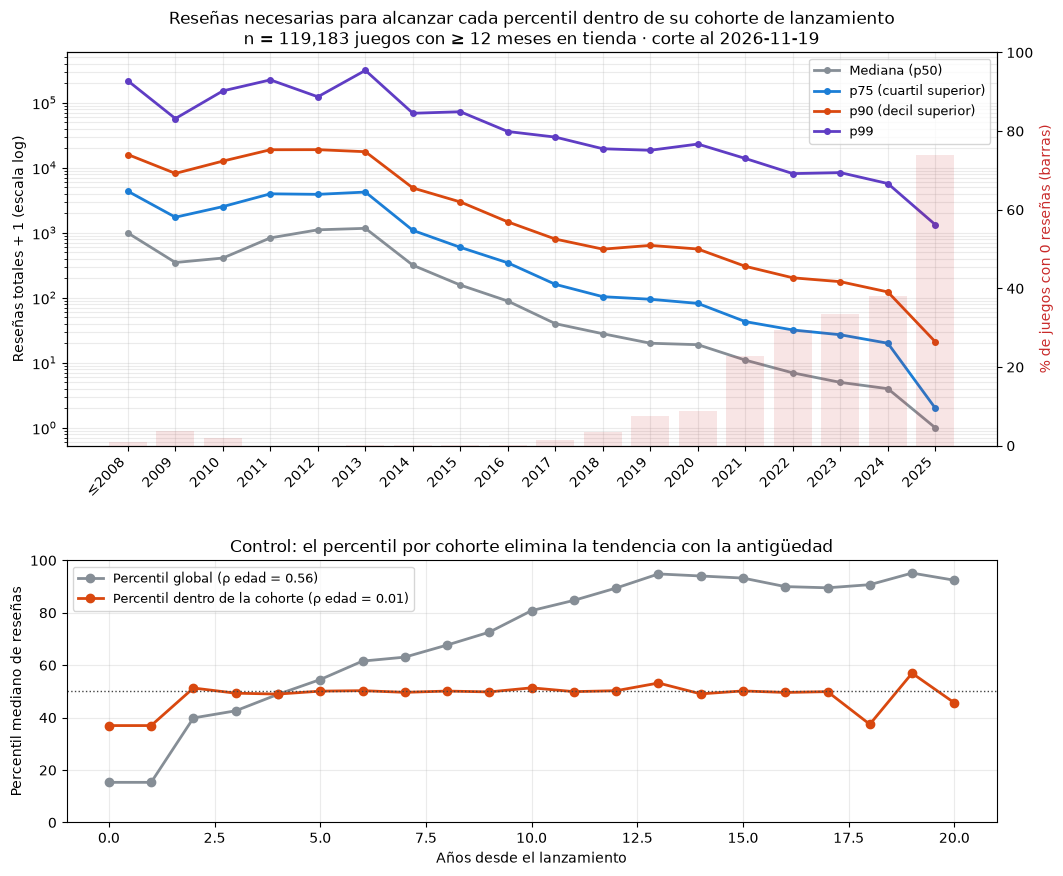

In [7]:
fig, (axThr, axAge) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [3, 2], 'hspace': 0.35})
xPos = np.arange(len(summaryDf))
for colName, color, label in [('p50', '#868E96', 'Mediana (p50)'), ('p75', '#1C7ED6', 'p75 (cuartil superior)'),
                              ('p90', '#D9480F', 'p90 (decil superior)'), ('p99', '#5F3DC4', 'p99')]:
    axThr.plot(xPos, summaryDf[colName] + 1, marker='o', ms=4, lw=2, color=color, label=label)
axThr.set_yscale('log')
axThr.set_xticks(xPos)
axThr.set_xticklabels(summaryDf['cohortLabel'], rotation=45, ha='right')
axThr.set_ylabel('Reseñas totales + 1 (escala log)')
axThr.set_title('Reseñas necesarias para alcanzar cada percentil dentro de su cohorte de lanzamiento\n'
                f'n = {len(workDf):,} juegos con ≥ {minAgeMonths} meses en tienda · corte al {snapshotDate.date()}',
                fontsize=12)
axThr.grid(alpha=0.25, which='both')
axThr.legend(fontsize=9)
axZero = axThr.twinx()
axZero.bar(xPos, summaryDf['pctZero'], color='#C92A2A', alpha=0.12, width=0.8)
axZero.set_ylabel('% de juegos con 0 reseñas (barras)', color='#C92A2A')
axZero.set_ylim(0, 100)

ageBin = np.floor(workDf['ageDays'] / 365.25).astype(int)
ageView = pd.DataFrame({'ageBin': ageBin, 'global': workDf['reviewPctlGlobal'], 'cohorte': workDf['reviewPctlCohort']})
ageMed = ageView.groupby('ageBin')[['global', 'cohorte']].median()
ageMed = ageMed[ageView['ageBin'].value_counts().sort_index() >= 30]
axAge.plot(ageMed.index, ageMed['global'], marker='o', color='#868E96', lw=2,
           label=f'Percentil global (ρ edad = {rhoGlobalPctl:.2f})')
axAge.plot(ageMed.index, ageMed['cohorte'], marker='o', color='#D9480F', lw=2,
           label=f'Percentil dentro de la cohorte (ρ edad = {rhoCohortPctl:.2f})')
axAge.axhline(50, color='#444', ls=':', lw=1)
axAge.set_xlabel('Años desde el lanzamiento')
axAge.set_ylabel('Percentil mediano de reseñas')
axAge.set_ylim(0, 100)
axAge.set_title('Control: el percentil por cohorte elimina la tendencia con la antigüedad', fontsize=12)
axAge.grid(alpha=0.25)
axAge.legend(fontsize=9, loc='upper left')
fig.savefig(figuresDir / 'percentilesCohorte.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusiones del notebook

- El percentil dentro de la cohorte elimina casi por completo la tendencia con la antigüedad: la correlación de Spearman baja de 0.555 (conteo crudo) a 0.006.
- Un umbral fijo no sirve: estar en el cuartil superior exige unas 4,231 reseñas en 2013 y solo 19 en 2024.
- La mediana de la proporción positiva sube de 0.74 (2014) a 0.88 (2024), así que la variable objetivo también debe compararse por cohorte o controlar el año.
- Hay ceros sospechosos en 2021–2024: de 22 % a 38 % de los juegos no tiene reseñas pese a llevar de 2 a 5 años en tienda. Falta auditarlos contra la tienda.
- La cohorte 2025 no es fiable: 74 % de sus juegos tiene 0 reseñas y la antigüedad sigue influyendo dentro del año (ρ ≈ 0.51). Esto respalda la decisión D-002 de excluir 2025 y 2026.
- El percentil se calcula con datos Post: es una variable objetivo, nunca un predictor.